# 02 — Análise Exploratória e Verificação da Amostra

**Objetivo.** Validar empiricamente as decisões amostrais da especificação (corte $p_{90}$ no valor
de mercado em $T$, minutagem mínima de 90 minutos, exclusão de goleiros e matriz de 12 categorias),
diagnosticar a qualidade dos dados (ausentes, defasagem das avaliações, cobertura das fontes) e
caracterizar a distribuição das variáveis-alvo $\Delta V$ e $\Delta V\%$ em $T+1$ e $T+2$.

**Entrada:** `data/raw/football_raw_dataset.parquet` (notebook 01).
**Saídas:** figuras em `reports/figures/02_eda/` (PNG, 300 dpi, largura de 16 cm, sem título embutido,
com índice de legendas em `figures_index.md`) e tabelas em `reports/tables/02_eda/` (CSV).

As regras de construção da amostra estão em `football_analytics.sample` e são as mesmas que o
notebook 03 aplicará. Este notebook apenas as executa e audita, e não grava a amostra filtrada.

**Convenções adotadas**

| Elemento | Definição operacional |
|---|---|
| Unidade de análise | jogador–temporada. Atletas transferidos dentro das Big Five têm os minutos somados e os atributos do clube com mais minutos |
| $V_T$, $V_{T+k}$ | último valor do Transfermarkt anterior ou igual a 30/jun do ano de término da temporada $T+k$, com defasagem máxima de 183 dias |
| Idade em $T$ | anos completos em 30/jun do ano de término de $T$ (mesma data-âncora de $V_T$) |
| Posição | posição granular do Transfermarkt agrupada em DEF/MEI/ATA (fallback: 1ª posição do FBref) |
| Faixas etárias | leitura formal dos intervalos da Tabela 6.2: $[16,23]$, $(23,28]$, $(28,32]$, $(32,\infty)$, isto é, 16–23, 24–28, 29–32 e 33+ anos completos |
| Corte $p_{90}$ | percentil 90 de $V_T$ **por temporada**, calculado após as exclusões de goleiros e de minutagem; mantém $V_T \le p_{90}$ |
| $\Delta V\%$ | $(V_{T+k}-V_T)/V_T \times 100$; também se reporta o log-retorno $\ln(V_{T+k}/V_T)$ |

## 0. Configuração

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import default_config
from football_analytics.io import load_table
from football_analytics.logging_utils import setup_logging

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "02_eda.log")
pl.setup_style()

FIG = pl.FigureRegistry(
    paths.figures("02_eda"),
    source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)",
)
TABLES = paths.tables("02_eda")
TABLES.mkdir(parents=True, exist_ok=True)


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    # utf-8-sig: abre com acentuação correta no Excel/Word
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.4f")


SEASONS = list(cfg.feature_seasons)
SEASON_LABELS = [sp.season_label(s) for s in SEASONS]
LEAGUES = list(sp.LEAGUE_LABELS)
POS = list(sp.POSITIONS)
BANDS = list(sp.AGE_BAND_LABELS)
CAT_LABELS = sp.category_labels()

In [2]:
raw = load_table(paths.final_dataset)
print(f"Dataset bruto: {len(raw):,} linhas x {raw.shape[1]} colunas")
assert not raw.duplicated(["season", "fbref_player_id", "fbref_team_id"]).any()

analytic = sp.build_analytic_sample(raw, sp.SampleRules(min_minutes=90, value_quantile=0.90, quantile_by="season"))
sample, funnel, p90 = analytic.sample, analytic.funnel, analytic.thresholds
universe = analytic.universe  # todo jogador–temporada de T, com as flags de cada etapa do funil
print(f"Amostra analítica: {len(sample):,} observações jogador–temporada, "
      f"{sample['fbref_player_id'].nunique():,} atletas únicos")

Dataset bruto: 16,873 linhas x 171 colunas


Amostra analítica: 9,810 observações jogador–temporada, 4,084 atletas únicos


## 1. Cobertura das fontes e qualidade da resolução de entidades

Antes de qualquer filtro, verifica-se a fração das linhas do FBref (jogadores de linha com pelo menos
90 minutos, temporadas de $T$) que foi pareada com cada fonte. Também se verifica por qual estágio do
algoritmo de resolução de entidades o par foi obtido. Esses números sustentam a subseção 5.2 da
especificação (*Desafios de coleta e fusão*).

In [3]:
target_rows = raw[~raw["is_lag_only"] & ~raw["is_goalkeeper"] & (raw["fb_minutes"] >= 90)]
coverage = (
    target_rows.assign(liga=target_rows["league"].map(sp.LEAGUE_LABELS))
    .groupby("liga")
    .agg(linhas=("fbref_player_id", "size"),
         transfermarkt=("tm_player_id", lambda s: s.notna().mean() * 100),
         understat=("understat_player_id", lambda s: s.notna().mean() * 100),
         sofascore=("sofascore_player_id", lambda s: s.notna().mean() * 100))
)
total = pd.DataFrame({
    "linhas": [len(target_rows)],
    "transfermarkt": [target_rows["tm_player_id"].notna().mean() * 100],
    "understat": [target_rows["understat_player_id"].notna().mean() * 100],
    "sofascore": [target_rows["sofascore_player_id"].notna().mean() * 100],
}, index=["Big Five"])
coverage = pd.concat([coverage, total])
save_csv(coverage, "tab01_cobertura_fontes")

methods = (raw[~raw["is_lag_only"]]
           .assign(metodo=lambda d: d["tm_match_method"].fillna("unmatched"))
           .groupby("metodo").size().rename("linhas").to_frame())
methods["%"] = methods["linhas"] / methods["linhas"].sum() * 100
methods = methods.sort_values("linhas", ascending=False)
save_csv(methods, "tab02_metodos_pareamento_tm")
display(coverage.round(1), methods.round(2))

,linhas,transfermarkt,understat,sofascore
Bundesliga,2045,100.00,99.30,99.80
La Liga,2411,99.90,99.20,99.00
Ligue 1,2288,99.90,99.20,99.60
Premier League,2231,100.00,99.70,99.80
Serie A,2424,100.00,99.50,99.50
Big Five,11399,100.00,99.40,99.50


,linhas,%
metodo,,
exact,13340,93.83
fuzzy,738,5.19
manual,99,0.70
unmatched,30,0.21
fuzzy_validated,8,0.06
league_fallback,2,0.01


**Leitura.** A resolução de entidades pareou com o Transfermarkt praticamente todo o universo-alvo
(100,0% das 11.399 linhas de jogadores de linha com ao menos 90 minutos), e com o Understat e o
Sofascore 99,4% e 99,5%. A distribuição por estágio do algoritmo mostra o seguinte:

- **93,8%** dos pares são correspondências exatas após a normalização de nomes (transliteração,
  remoção de diacríticos e de pontuação).
- **5,2%** foram obtidos por similaridade difusa (Levenshtein + Jaro-Winkler) sob as restrições de
  clube, temporada e ano de nascimento.
- **0,7%** dependeram da tabela de correspondências manuais.

Os casos manuais são justamente os três tipos de ruído previstos na subseção 5.2 da especificação:

- **Apelidos sem relação grafométrica com o nome civil:** *Pepelu* = José Luis García Vayá,
  *Simy* = Simeon Nwankwo, *Chicharito* = Javier Hernández, *Cote* = José Ángel.
- **Sobrenomes diferentes entre as fontes:** Jonny Castro/Otto, Samir Santos/Caetano.
- **Transliterações:** Babis/Charalampos Lykogiannis, Mircea/Alexandru Țîrlea.

Restam 0,2% de linhas sem par, quase todas de atletas com poucos minutos.

*Sugestão para o texto (Metodologia, 5.2):* "O pareamento automático resolveu 99,0% dos
registros; os 0,7% restantes, majoritariamente apelidos sem semelhança ortográfica com o nome
civil, foram resolvidos por uma tabela de correspondências auditada manualmente."

## 2. Funil amostral

Os filtros da especificação (§2 da *Verificação dos Dados*) são aplicados em sequência: pareamento
com o Transfermarkt, exclusão de goleiros, minutagem mínima, existência de $V_T$ e corte $p_{90}$.
A tabela compara a atrição observada com as ordens de grandeza estimadas na especificação.

,etapa,observacoes,atletas_unicos,retencao_etapa_pct,retencao_acumulada_pct,especificacao
0,Registros FBref (jogador–clube–temporada),14217,5483,NaN,NaN,≈ 21.200 (N₀)
1,Jogador–temporada,13544,5483,95.27,100.00,—
2,Pareados com o Transfermarkt,13514,5462,99.78,99.78,≈ 18.500 (N₁)
3,Exclusão de goleiros,12496,5049,92.47,92.26,≈ 16.800 (N₂)
4,Minutagem ≥ 90 min em T,10966,4248,87.76,80.97,≈ 12.400 (N₃)
5,Com valor de mercado em T,10824,4180,98.71,79.92,—
6,Corte p90 de V_T,9810,4084,90.63,72.43,10.350 obs.; 4.217 atletas


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig01_funil_amostral.png


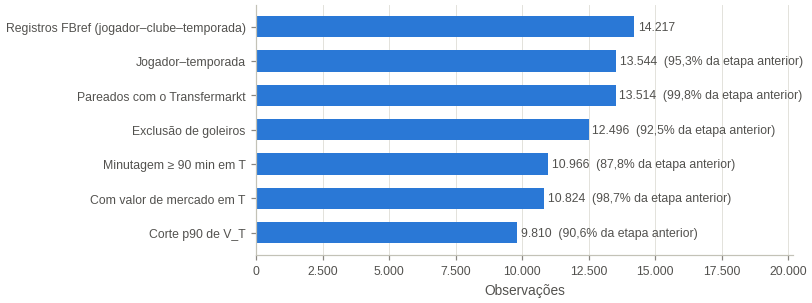

In [4]:
spec_estimate = {
    "Registros FBref (jogador–clube–temporada)": "≈ 21.200 (N₀)",
    "Pareados com o Transfermarkt": "≈ 18.500 (N₁)",
    "Exclusão de goleiros": "≈ 16.800 (N₂)",
    "Minutagem ≥ 90 min em T": "≈ 12.400 (N₃)",
    "Corte p90 de V_T": "10.350 obs.; 4.217 atletas",
}
funnel_tab = funnel.assign(especificacao=funnel["etapa"].map(spec_estimate).fillna("—"))
save_csv(funnel_tab, "tab03_funil_amostral", index=False)
display(funnel_tab)

fig, ax = plt.subplots(figsize=pl.figsize(7.5))
steps = funnel.iloc[::-1].reset_index(drop=True)
ax.barh(steps.index, steps["observacoes"], color=pl.BLUE, height=0.62)
ax.set_yticks(steps.index, steps["etapa"])
ax.xaxis.set_major_formatter(pl.br_formatter(0))
ax.set_xlabel("Observações")
ax.grid(axis="y", visible=False)
xmax = steps["observacoes"].max()
for i, row in steps.iterrows():
    txt = pl.br(row["observacoes"], 0)
    if pd.notna(row["retencao_etapa_pct"]):
        txt += f"  ({pl.br_pct(row['retencao_etapa_pct'], 1)} da etapa anterior)"
    ax.text(row["observacoes"] + xmax * 0.01, i, txt, va="center", fontsize=8, color=pl.INK_SECONDARY)
ax.set_xlim(0, xmax * 1.42)
FIG.save(fig, "fig01_funil_amostral",
         "Funil de seleção da amostra analítica (Big Five, 2019/20–2023/24)",
         note="Da segunda barra em diante, a unidade é jogador–temporada.")
plt.show()

**Leitura.** A amostra analítica final contém **9.810 observações jogador–temporada de 4.084
atletas únicos**. Esses valores ficam muito próximos das ordens de grandeza projetadas na
especificação (10.350 observações e 4.217 atletas). As etapas de atrição são as seguintes:

1. **Consolidação jogador–temporada** (−4,7%). Os 14.217 registros do FBref viram 13.544 unidades,
   porque atletas transferidos entre clubes das Big Five na mesma temporada têm um único valor de
   mercado (604 deles estão na amostra final).
2. **Pareamento com o Transfermarkt** (99,8% retidos).
3. **Exclusão de goleiros** (−7,5%).
4. **Minutagem mínima** (−12,2%). É o filtro que mais remove observações.
5. **Existência de $V_T$** (98,7% retidos). Das 142 observações sem valor, 70 são de atletas
   recém-incluídos na tabela de correspondências manuais. A coleta deles no Transfermarkt foi
   interrompida por um bloqueio temporário de acesso, e eles serão incorporados numa reexecução
   do notebook 01.
6. **Corte $p_{90}$** (−9,4%).

As estimativas intermediárias da especificação ($N_0 \approx 21.200$, $N_1 \approx 18.500$)
pressupunham o elenco inteiro inscrito, inclusive atletas sem minutos. Aqui, o universo de partida
é o FBref, que só lista quem entrou em campo. Convém ajustar a redação do funil no artigo aos
valores observados (Tabela `tab03_funil_amostral.csv`).

## 3. Valor de mercado em $T$ e o corte $p_{90}$

A especificação ancora o corte no limiar empírico de **€ 18 milhões** reportado por Müller et al.
(2017) para o percentil 90 das transações. Verifica-se aqui (i) a forma da distribuição de $V_T$,
(ii) o limiar efetivo por temporada e por liga e (iii) quem o corte exclui. O corte é calculado
**por temporada** porque o nível geral de preços do Transfermarkt varia no tempo (por exemplo, a
revisão generalizada para baixo de abril de 2020, na pandemia). Um limiar fixo excluiria proporções
diferentes de atletas em cada ano.

In [5]:
eligible = universe[universe["passes_value"]].copy()
q = (eligible.groupby("season")["tm_value_T"]
     .describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
     [["count", "mean", "50%", "75%", "90%", "95%", "99%", "max"]])
q.index = [sp.season_label(s) for s in q.index]
pooled_p90 = eligible["tm_value_T"].quantile(0.9)
q.loc["Agrupado"] = eligible["tm_value_T"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])[q.columns]
q["acima_de_18mi_%"] = list(eligible.groupby("season")["tm_value_T"].apply(lambda s: (s > 18e6).mean() * 100)) + [
    (eligible["tm_value_T"] > 18e6).mean() * 100]
excl = eligible.assign(excl=~eligible["in_sample"]).groupby("season")["excl"].mean() * 100
q["excluidos_pelo_corte_%"] = list(excl) + [(~eligible["in_sample"]).mean() * 100]
save_csv(q, "tab04_distribuicao_vt_p90")
display((q / [1, 1e6, 1e6, 1e6, 1e6, 1e6, 1e6, 1e6, 1, 1]).round(2).rename(
    columns=lambda c: c if c in ("count", "acima_de_18mi_%", "excluidos_pelo_corte_%") else f"{c} (€ mi)"))
print(f"Limiar p90 agrupado (todas as temporadas): €{pooled_p90 / 1e6:.1f} mi")
print("Limiar p90 por temporada (€ mi):", (p90 / 1e6).round(1).to_dict())
skew_raw, skew_log = stats.skew(eligible["tm_value_T"]), stats.skew(np.log10(eligible["tm_value_T"]))
print(f"Assimetria de V_T: {skew_raw:.2f} (nível) vs {skew_log:.2f} (log10)")

,count,mean (€ mi),50% (€ mi),75% (€ mi),90% (€ mi),95% (€ mi),99% (€ mi),max (€ mi),acima_de_18mi_%,excluidos_pelo_corte_%
2019/20,"2,092.00",10.97,5.40,13.50,28.00,40.00,72.00,180.00,17.30,9.08
2020/21,"2,188.00",11.24,5.00,14.00,30.00,42.00,75.00,160.00,18.60,8.68
2021/22,"2,216.00",10.95,5.00,15.00,27.00,40.00,74.25,160.00,17.60,9.88
2022/23,"2,175.00",11.99,6.00,15.00,30.00,42.00,81.30,180.00,19.31,9.20
2023/24,"2,153.00",12.79,6.00,15.00,32.00,50.00,87.40,180.00,20.72,9.99
Agrupado,"10,824.00",11.59,5.00,15.00,30.00,44.85,80.00,180.00,18.71,9.37


Limiar p90 agrupado (todas as temporadas): €30.0 mi
Limiar p90 por temporada (€ mi): {'1920': 28.0, '2021': 30.0, '2122': 27.0, '2223': 30.0, '2324': 32.0}
Assimetria de V_T: 3.39 (nível) vs -0.03 (log10)


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig02_distribuicao_vt.png


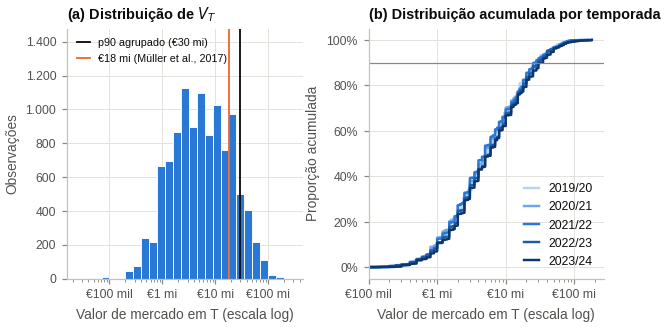

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(7.5), gridspec_kw={"wspace": 0.28})
# Classes largas em log10: o Transfermarkt publica valores arredondados, e classes finas viram "pente".
bins = 10 ** np.arange(4.4, 8.5, 0.15)
ax1.hist(eligible["tm_value_T"], bins=bins, color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.6)
ax1.set_xscale("log")
ax1.axvline(pooled_p90, color=pl.INK, linewidth=1.2, label=f"p90 agrupado (€{pl.br(pooled_p90 / 1e6, 0)} mi)")
ax1.axvline(18e6, color=pl.ORANGE, linewidth=1.2, label="€18 mi (Müller et al., 2017)")
ax1.set_ylim(top=ax1.get_ylim()[1] * 1.25)
ax1.legend(loc="upper left", fontsize=7, handlelength=1.2)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(pl.euro_millions))
ax1.set_xlabel("Valor de mercado em T (escala log)")
ax1.set_ylabel("Observações")
ax1.yaxis.set_major_formatter(pl.br_formatter(0))
ax1.set_title("(a) Distribuição de $V_T$")

ramp = ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]
for color, season in zip(ramp, SEASONS):
    v = np.sort(eligible.loc[eligible["season"] == season, "tm_value_T"].to_numpy())
    ax2.plot(v, np.arange(1, len(v) + 1) / len(v), color=color, linewidth=1.6, label=sp.season_label(season))
ax2.axhline(0.9, color=pl.INK_MUTED, linewidth=0.8)
ax2.set_xscale("log")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(pl.euro_millions))
ax2.yaxis.set_major_formatter(pl.pct_formatter(0, scale=1))
ax2.set_xlabel("Valor de mercado em T (escala log)")
ax2.set_ylabel("Proporção acumulada")
ax2.set_title("(b) Distribuição acumulada por temporada")
ax2.legend(loc="lower right", handlelength=1.2)
ax2.set_xlim(left=1e5)
FIG.save(fig, "fig02_distribuicao_vt",
         "Distribuição do valor de mercado em T e limiar do percentil 90",
         note="Jogadores de linha com ≥ 90 minutos e V_T observado. Em (b), a linha horizontal marca 90%.")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig03_p90_liga_temporada.png


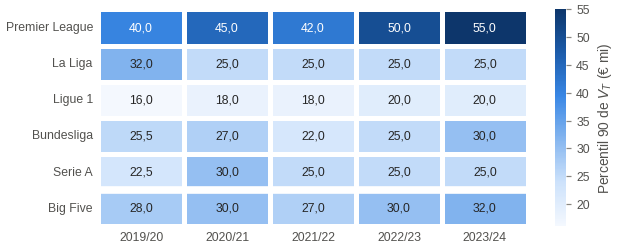

In [7]:
p90_lt = eligible.groupby(["league", "season"])["tm_value_T"].quantile(0.9).unstack("season")
p90_lt.index = p90_lt.index.map(sp.LEAGUE_LABELS)
p90_lt.loc["Big Five"] = p90
p90_lt.columns = SEASON_LABELS
save_csv(p90_lt / 1e6, "tab05_p90_liga_temporada_mi")

fig, ax = plt.subplots(figsize=pl.figsize(6.5))
data = p90_lt / 1e6
sns.heatmap(data, annot=pl.annotations(data, 1), fmt="", cmap=pl.SEQUENTIAL, cbar_kws={"label": "Percentil 90 de $V_T$ (€ mi)"},
            linewidths=2, linecolor=pl.SURFACE, ax=ax, annot_kws={"fontsize": 8})
ax.axhline(len(data) - 1, color=pl.SURFACE, linewidth=5)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.grid(False)
FIG.save(fig, "fig03_p90_liga_temporada",
         "Percentil 90 do valor de mercado em T por liga e temporada (€ milhões)",
         note="A linha 'Big Five' é o limiar efetivamente aplicado (calculado por temporada sobre as cinco ligas).")
plt.show()

In [8]:
# Sensibilidade da regra de corte: quantas observações cada alternativa mantém e quem ela exclui.
lt_p90 = eligible.groupby(["league", "season"])["tm_value_T"].transform(lambda s: s.quantile(0.9))
scenarios = [
    ("p90 por temporada (adotado)", eligible["tm_value_T"] <= eligible["season"].map(p90),
     f"€{pl.br(p90.min() / 1e6, 0)}–{pl.br(p90.max() / 1e6, 0)} mi"),
    ("p90 único (temporadas agrupadas)", eligible["tm_value_T"] <= pooled_p90, f"€{pl.br(pooled_p90 / 1e6, 0)} mi"),
    ("Limiar fixo de €18 mi (Müller et al., 2017)", eligible["tm_value_T"] <= 18e6, "€18 mi"),
    ("p90 por liga e temporada", eligible["tm_value_T"] <= lt_p90,
     f"€{pl.br(lt_p90.min() / 1e6, 0)}–{pl.br(lt_p90.max() / 1e6, 0)} mi"),
]
sens = []
for name, kept_mask, thr in scenarios:
    kept, out = eligible[kept_mask], eligible[~kept_mask]
    sens.append({
        "cenario": name, "limiar": thr, "obs_mantidas": len(kept), "pct_mantido": len(kept) / len(eligible) * 100,
        "pct_premier_league_na_amostra": (kept["league"] == "ENG-Premier League").mean() * 100,
        "mediana_dvpct_T1_mantidos": kept["delta_v_pct_T1"].median(),
        "mediana_dvpct_T1_excluidos": out["delta_v_pct_T1"].median(),
        "pct_valorizou_T1_mantidos": (kept["delta_v_T1"].dropna() > 0).mean() * 100,
        "pct_valorizou_T1_excluidos": (out["delta_v_T1"].dropna() > 0).mean() * 100,
    })
sens = pd.DataFrame(sens).set_index("cenario")
save_csv(sens, "tab05b_sensibilidade_corte_p90")
sens.round(1)

,limiar,obs_mantidas,pct_mantido,pct_premier_league_na_amostra,mediana_dvpct_T1_mantidos,mediana_dvpct_T1_excluidos,pct_valorizou_T1_mantidos,pct_valorizou_T1_excluidos
cenario,,,,,,,,
p90 por temporada (adotado),€27–32 mi,9810,90.60,17.20,-20.00,-11.10,27.60,31.60
p90 único (temporadas agrupadas),€30 mi,9851,91.00,17.20,-20.00,-10.70,27.70,31.20
"Limiar fixo de €18 mi (Müller et al., 2017)",€18 mi,8799,81.30,14.90,-20.00,-11.10,27.20,31.60
p90 por liga e temporada,€16–55 mi,9865,91.10,19.70,-20.00,-10.70,27.50,32.80


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig04_perfil_excluidos_p90.png


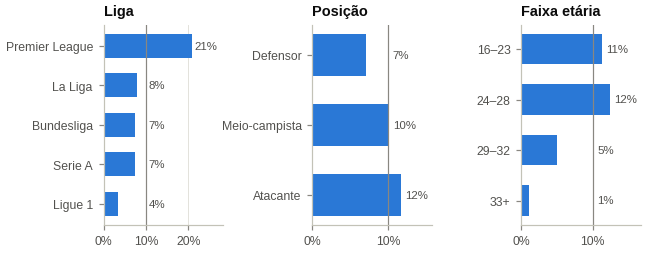

,season,fb_player,fb_team,position_group,age_T,tm_value_T
1812,2324,Erling Haaland,Manchester City,ATA,23,180.00
2571,2324,Jude Bellingham,Real Madrid,MEI,21,180.00
5491,1920,Kylian Mbappé,Paris SG,ATA,21,180.00
1164,2223,Erling Haaland,Manchester City,ATA,22,180.00
4143,2324,Vinicius Júnior,Real Madrid,ATA,23,180.00
3098,2324,Kylian Mbappé,Paris SG,ATA,25,180.00
1017,2223,Kylian Mbappé,Paris SG,ATA,24,180.00
551,2122,Kylian Mbappé,Paris SG,ATA,23,160.00
2369,2021,Kylian Mbappé,Paris SG,ATA,22,160.00
1002,2223,Vinicius Júnior,Real Madrid,ATA,22,150.00


In [9]:
el = eligible.assign(excluido=~eligible["in_sample"],
                     liga=eligible["league"].map(sp.LEAGUE_LABELS),
                     posicao=eligible["position_group"].map(sp.POSITION_LABELS))
share = {
    "Liga": el.groupby("liga")["excluido"].mean().sort_values() * 100,
    "Posição": el.groupby("posicao")["excluido"].mean().reindex([sp.POSITION_LABELS[p] for p in POS]) * 100,
    "Faixa etária": el.groupby("age_band", observed=True)["excluido"].mean() * 100,
}
save_csv(pd.concat(share, names=["dimensao", "grupo"]).rename("pct_acima_p90").to_frame(), "tab06_perfil_excluidos_p90")

fig, axes = plt.subplots(1, 3, figsize=pl.figsize(6), gridspec_kw={"wspace": 0.75})
for ax, (title, s) in zip(axes, share.items()):
    s = s.iloc[::-1] if title != "Liga" else s
    ax.barh(range(len(s)), s.values, color=pl.BLUE, height=0.6)
    ax.set_yticks(range(len(s)), [str(i) for i in s.index])
    ax.axvline(10, color=pl.INK_MUTED, linewidth=0.8, zorder=1)
    for i, v in enumerate(s.values):
        # rótulo sempre à direita da linha de referência, para não colidir com ela
        ax.text(max(v, 10) + 0.6, i, pl.br_pct(v, 0), va="center", fontsize=7.5, color=pl.INK_SECONDARY)
    ax.set_xlim(0, max(s.max() * 1.35, 14))
    ax.xaxis.set_major_formatter(pl.pct_formatter(0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
FIG.save(fig, "fig04_perfil_excluidos_p90",
         "Proporção de observações acima do percentil 90 (excluídas) por liga, posição e faixa etária",
         note="A linha vertical marca 10%, a proporção esperada sob exclusão uniforme.")
plt.show()

top_excluded = (el[el["excluido"]].sort_values("tm_value_T", ascending=False)
                [["season", "fb_player", "fb_team", "position_group", "age_T", "tm_value_T"]].head(10))
display(top_excluded.assign(tm_value_T=lambda d: d["tm_value_T"] / 1e6))

**Leitura.** A distribuição de $V_T$ é fortemente assimétrica à direita: o coeficiente de assimetria
é 3,39 em nível, mas cai a −0,03 em escala logarítmica. Ou seja, $V_T$ é aproximadamente
log-normal, o que justifica a transformação $\log(1+x)$ prevista na Metodologia.

**O limiar empírico do percentil 90 é bem maior que os € 18 milhões de Müller et al. (2017).**
Ele varia de € 27 mi (2021/22) a € 32 mi (2023/24), e é de € 30 mi com as temporadas agrupadas. Na
amostra deste estudo, € 18 mi corresponde aproximadamente ao **percentil 81**: 18,7% das
observações ficam acima. A diferença reflete o universo de referência e a inflação do mercado.
Müller et al. trabalham com transações realizadas até 2016, e aqui se usa o estoque de atletas
avaliados entre 2020 e 2024. A especificação deve ser redigida para tratar € 18 mi como referência
histórica e o $p_{90}$ como regra operacional. A Figura 2(b) mostra que as distribuições
acumuladas das cinco temporadas são quase sobrepostas, de modo que o limiar por temporada e o
limiar único produzem amostras quase idênticas (9.810 contra 9.851 observações).

**O corte não é neutro entre ligas** (Figuras 3 e 4):

- O $p_{90}$ interno da Premier League chega a € 55 mi em 2023/24, contra € 20 mi na Ligue 1.
- Por isso, **21% das observações da Premier League** são excluídas, contra 4% da Ligue 1.
- A exclusão também é maior entre atacantes (12%) e entre atletas de até 28 anos (11–12%), e quase
  nula entre os de 33 anos ou mais (1%).

Isso é coerente com a motivação teórica do corte (prêmios de *branding* concentrados em atacantes
jovens dos clubes mais ricos). Como consequência, porém, a Premier League fica sub-representada
na amostra final (17,2%). A tabela de sensibilidade mostra que um corte por liga e temporada
restauraria a participação inglesa (19,7%) praticamente sem alterar o tamanho da amostra. Essa
alternativa pode ser apresentada como **teste de robustez** no capítulo de resultados.

Os atletas excluídos não se distinguem dos mantidos pela direção da variação seguinte: 31,6% se
valorizam em $T+1$, contra 27,6% dos mantidos. A diferença maior está na **escala** do $\Delta V$
absoluto, o que reforça o uso de $\Delta V\%$ como alvo primário.

## 4. Minutagem mínima ($\ge 90$ minutos)

O filtro de 90 minutos elimina as observações em que as taxas por 90 minutos seriam dominadas por
ruído amostral. Como a taxa por 90 minutos de uma contagem é a contagem dividida por
$\text{minutos}/90$, um atleta com 30 minutos e um único gol registra 3 gols/90. O gráfico (b) mostra
quem esse filtro remove.

Jogadores de linha pareados com V_T: 12,125; abaixo de 90 min: 1,301 (10.7%)


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig05_minutagem.png


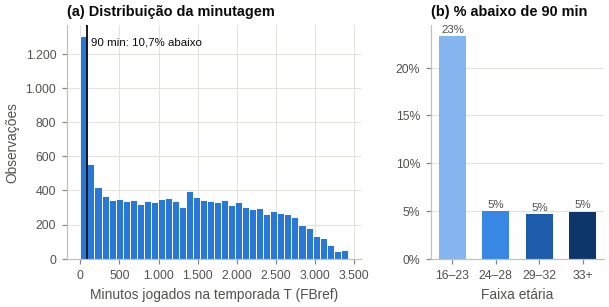

In [10]:
outfield = universe[universe["passes_outfield"] & (universe["tm_value_T"] > 0)].copy()
below = outfield["fb_minutes"] < 90
print(f"Jogadores de linha pareados com V_T: {len(outfield):,}; abaixo de 90 min: {below.sum():,} ({below.mean() * 100:.1f}%)")
by_band = outfield.assign(below=below).groupby("age_band", observed=True)["below"].mean() * 100
by_pos = outfield.assign(below=below).groupby("position_group")["below"].mean().reindex(POS) * 100
save_csv(pd.concat({"faixa_etaria": by_band, "posicao": by_pos}).rename("pct_abaixo_90min").to_frame(),
         "tab07_abaixo_90min")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(7), gridspec_kw={"width_ratios": [1.7, 1], "wspace": 0.3})
ax1.hist(outfield["fb_minutes"], bins=np.arange(0, 3500, 90), color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.6)
ax1.axvline(90, color=pl.INK, linewidth=1.2)
ax1.text(140, ax1.get_ylim()[1] * 0.95, f"90 min: {pl.br_pct(below.mean() * 100, 1)} abaixo", va="top", fontsize=7.5)
ax1.xaxis.set_major_formatter(pl.br_formatter(0))
ax1.yaxis.set_major_formatter(pl.br_formatter(0))
ax1.set_xlabel("Minutos jogados na temporada T (FBref)")
ax1.set_ylabel("Observações")
ax1.set_title("(a) Distribuição da minutagem")
ax2.bar(range(len(by_band)), by_band.values, color=pl.AGE_BAND_COLORS, width=0.62)
ax2.set_xticks(range(len(by_band)), by_band.index)
for i, v in enumerate(by_band.values):
    ax2.text(i, v + 0.4, pl.br_pct(v, 0), ha="center", fontsize=7.5, color=pl.INK_SECONDARY)
ax2.yaxis.set_major_formatter(pl.pct_formatter(0))
ax2.set_xlabel("Faixa etária")
ax2.set_title("(b) % abaixo de 90 min")
ax2.grid(axis="x", visible=False)
FIG.save(fig, "fig05_minutagem",
         "Distribuição dos minutos jogados em T e proporção de observações abaixo de 90 minutos por faixa etária",
         note="Jogadores de linha pareados com o Transfermarkt e com V_T observado; classes de 90 minutos.")
plt.show()

**Leitura.** Entre os jogadores de linha pareados e com $V_T$, **10,7% têm menos de 90 minutos** na
temporada. A remoção é fortemente concentrada nos **16–23 anos (23% da faixa)**, contra cerca de 5%
nas demais. Esse é o efeito esperado do filtro: atletas da base promovidos ao elenco principal
acumulam aparições esporádicas, cujas taxas por 90 minutos seriam ruído.

A consequência metodológica é que o filtro **seleciona os jovens já integrados ao elenco**, e não
o universo dos jovens com potencial. A conclusão sobre a categoria C1–C3 deve ser lida como
"jovens com minutagem na elite", uma limitação de generalização a registrar no artigo.

Acima de 90 minutos a distribuição é aproximadamente uniforme até cerca de 2.500 minutos, e o
limiar não corta nenhuma concentração natural de massa. Isso sustenta o valor de 90 minutos
como piso, e não como regra de seleção substantiva.

## 5. Valores ausentes na amostra analítica

O mapa mostra, por temporada, a proporção de ausentes nas variáveis previstas para o vetor
explicativo e para os alvos. Há três origens de ausência, e cada uma recebe tratamento diferente no
notebook 03:

1. **Estrutural da fonte.** Métrica não publicada naquela temporada (p. ex. recuperações de bola no
   Sofascore em 2019/20).
2. **Pareamento.** Atleta sem par no Understat ou no Sofascore.
3. **Ausência informativa do alvo.** $V_{T+k}$ inexistente porque o atleta deixou de ser avaliado
   (aposentadoria, ligas sem cobertura). Esse caso implica viés de sobrevivência e não deve ser
   imputado.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig06_ausentes.png


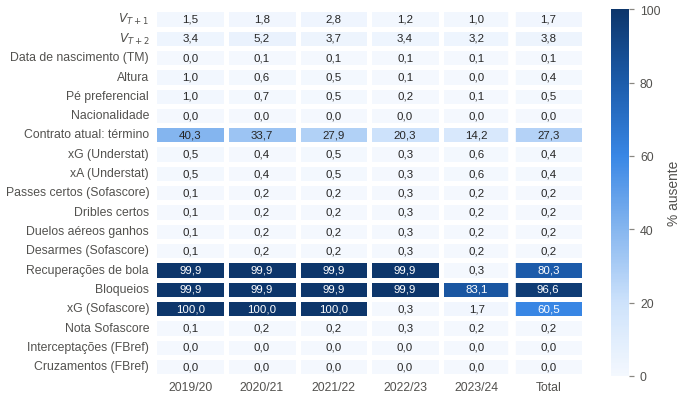

In [11]:
missing_vars = {
    "$V_{T+1}$": "tm_value_T1", "$V_{T+2}$": "tm_value_T2",
    "Data de nascimento (TM)": "tm_birth_date", "Altura": "tm_height_cm", "Pé preferencial": "tm_foot",
    "Nacionalidade": "tm_nationalities", "Contrato atual: término": "tm_profile_contract_expires",
    "xG (Understat)": "us_xg", "xA (Understat)": "us_xa",
    "Passes certos (Sofascore)": "ss_accurate_passes", "Dribles certos": "ss_successful_dribbles",
    "Duelos aéreos ganhos": "ss_aerial_duels_won", "Desarmes (Sofascore)": "ss_tackles",
    "Recuperações de bola": "ss_ball_recovery", "Bloqueios": "ss_outfielder_blocks",
    "xG (Sofascore)": "ss_expected_goals", "Nota Sofascore": "ss_rating",
    "Interceptações (FBref)": "fb_interceptions", "Cruzamentos (FBref)": "fb_crosses",
}
miss = pd.DataFrame({
    label: sample.groupby("season")[col].apply(lambda s: s.isna().mean() * 100) for label, col in missing_vars.items()
}).T
miss.columns = SEASON_LABELS
miss["Total"] = [sample[c].isna().mean() * 100 for c in missing_vars.values()]
save_csv(miss, "tab08_ausentes_amostra")

fig, ax = plt.subplots(figsize=pl.figsize(11))
sns.heatmap(miss, annot=pl.annotations(miss, 1), fmt="", cmap=pl.SEQUENTIAL, vmin=0, vmax=100, linewidths=2,
            linecolor=pl.SURFACE, cbar_kws={"label": "% ausente"}, ax=ax, annot_kws={"fontsize": 7.5})
ax.axvline(len(SEASONS), color=pl.SURFACE, linewidth=5)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.grid(False)
FIG.save(fig, "fig06_ausentes",
         "Proporção de valores ausentes por variável e temporada na amostra analítica (%)")
plt.show()

In [12]:
# Varredura completa: métricas com mais de 5% de ausentes em alguma temporada da amostra analítica.
metric_cols = [c for c in sample.columns if c.startswith(("fb_", "us_", "ss_"))
               and pd.api.types.is_numeric_dtype(sample[c]) and not c.endswith(("_match_score",))]
miss_all = sample.groupby("season")[metric_cols].apply(lambda d: d.isna().mean() * 100).T
miss_all.columns = SEASON_LABELS
flagged = miss_all[miss_all.max(axis=1) > 5].sort_values(SEASON_LABELS[0], ascending=False)
save_csv(miss_all, "tab08b_ausentes_todas_metricas")
flagged.round(1)

,2019/20,2020/21,2021/22,2022/23,2023/24
fb_pens_conceded,100.00,100.00,100.00,100.00,100.00
fb_pens_won,100.00,100.00,100.00,100.00,100.00
ss_expected_assists,100.00,100.00,100.00,0.30,0.20
ss_expected_goals,100.00,100.00,100.00,0.30,1.70
ss_ball_recovery,99.90,99.90,99.90,99.90,0.30
ss_outfielder_blocks,99.90,99.90,99.90,99.90,83.10
fb_goals_per_shot_on_target,18.20,16.40,16.80,15.70,14.30
fb_minutes_per_sub,12.90,11.40,9.80,7.90,8.10


In [13]:
# Ausência do alvo por faixa etária: o viés de sobrevivência se concentra nos veteranos.
target_av = sample.groupby("age_band", observed=True)[["tm_value_T1", "tm_value_T2"]].apply(
    lambda d: d.isna().mean() * 100).rename(columns={"tm_value_T1": "sem_V_T+1_%", "tm_value_T2": "sem_V_T+2_%"})
save_csv(target_av, "tab09_ausencia_alvo_faixa")
target_av.round(1)

,sem_V_T+1_%,sem_V_T+2_%
age_band,,
16–23,0.30,0.50
24–28,0.50,0.90
29–32,1.70,3.90
33+,9.70,24.00


**Leitura.** Os ausentes da amostra analítica são poucos e têm padrão estrutural claro:

- **Atributos demográficos** (nascimento, altura, pé, nacionalidade) e as métricas do Understat,
  do Sofascore e do FBref: menos de 1% de ausência.
- **Recuperações de bola, bloqueios e o xG/xA do Sofascore:**
  - o xG/xA só existe a partir de 2022/23;
  - as recuperações só existem em 2023/24;
  - os bloqueios faltam em 83% das observações mesmo em 2023/24.

  Nas temporadas anteriores, a ausência é ≥ 99,9%. Por isso **devem ser descartados** como
  *features*: imputá-los criaria um sinal artificial de temporada. O xG/xA vem do Understat, que
  cobre as cinco temporadas.
- **Término do contrato atual** (27,3% ausente, chegando a 40,3% em 2019/20): o dado é o contrato
  vigente hoje, e atletas aposentados ou sem clube não o possuem. Como o contrato vigente em $T$
  não é observável retroativamente no Transfermarkt, o notebook 03 o estimará a partir da data de
  chegada ao clube, da última renovação e do histórico de transferências, com uma *flag* de
  estimativa.
- **Alvos:** $V_{T+1}$ e $V_{T+2}$ faltam em 1,7% e 3,8% das observações, mas a ausência é
  **informativa**. Ela chega a 9,7% e 24,0% entre os atletas de 33 anos ou mais (aposentadoria
  ou saída para ligas sem avaliação). Há, portanto, **viés de sobrevivência** nos alvos dos
  veteranos: o $\Delta V$ observado nas categorias C10–C12 é o dos que continuaram sendo avaliados
  e, provavelmente, **subestima** a depreciação real. O tratamento recomendado é excluir as linhas
  sem alvo, sem imputação, e reportar a limitação.

As colunas `fb_pens_won` e `fb_pens_conceded` estão vazias em todas as temporadas porque eram dados
Opta e foram retiradas do FBref.

## 6. Matriz de 12 categorias (4 faixas etárias × 3 posições)

O treinamento segmentado exige tamanho amostral suficiente em cada célula, e mais ainda na janela
expandida, em que a primeira dobra treina com uma única temporada. A figura mostra o $N$ por
categoria na amostra analítica, e a tabela o desagrega por temporada.

,2019/20,2020/21,2021/22,2022/23,2023/24,Total,% amostra,com alvo T+1,com alvo T+2
C1 · DEF 16–23,186,206,199,198,175,964,9.80,963,962
C2 · MEI 16–23,155,179,156,166,188,844,8.60,841,839
C3 · ATA 16–23,155,158,172,163,178,826,8.40,821,819
C4 · DEF 24–28,318,305,310,317,317,1567,16.00,1563,1554
C5 · MEI 24–28,232,239,264,250,247,1232,12.60,1224,1220
C6 · ATA 24–28,217,209,212,226,219,1083,11.00,1074,1072
C7 · DEF 29–32,180,204,213,193,198,988,10.10,973,955
C8 · MEI 29–32,160,159,145,145,133,742,7.60,725,705
C9 · ATA 29–32,123,129,128,119,104,603,6.10,596,582
C10 · DEF 33+,78,87,72,78,74,389,4.00,355,291


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig07_matriz_12_categorias.png


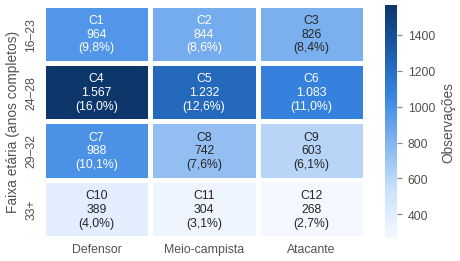

In [14]:
cat_counts = (sample.groupby(["age_band", "position_group"], observed=True).size()
              .unstack("position_group").reindex(columns=POS))
cat_season = sample.groupby(["category", "season"]).size().unstack("season").reindex(list(CAT_LABELS))
cat_season.index = [CAT_LABELS[c] for c in cat_season.index]
cat_season.columns = SEASON_LABELS
cat_season["Total"] = cat_season.sum(axis=1)
cat_season["% amostra"] = cat_season["Total"] / cat_season["Total"].sum() * 100
cat_t1 = sample[sample["delta_v_pct_T1"].notna()].groupby("category").size()
cat_t2 = sample[sample["delta_v_pct_T2"].notna()].groupby("category").size()
cat_season["com alvo T+1"] = [cat_t1.get(c, 0) for c in CAT_LABELS]
cat_season["com alvo T+2"] = [cat_t2.get(c, 0) for c in CAT_LABELS]
save_csv(cat_season, "tab10_categorias_por_temporada")
display(cat_season.round(1))

fig, ax = plt.subplots(figsize=pl.figsize(7, 12))
annot = cat_counts.apply(lambda col: [
    f"C{b * 3 + POS.index(col.name) + 1}\n{pl.br(v, 0)}\n({pl.br_pct(v / len(sample) * 100, 1)})"
    for b, v in enumerate(col)])
sns.heatmap(cat_counts, annot=annot, fmt="", cmap=pl.SEQUENTIAL, linewidths=2, linecolor=pl.SURFACE,
            cbar_kws={"label": "Observações"}, ax=ax, annot_kws={"fontsize": 8})
ax.set_xticklabels([sp.POSITION_LABELS[p] for p in POS])
ax.set_xlabel("")
ax.set_ylabel("Faixa etária (anos completos)")
ax.tick_params(length=0)
ax.grid(False)
FIG.save(fig, "fig07_matriz_12_categorias",
         "Distribuição da amostra analítica na matriz de 12 categorias (faixa etária × posição)")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig08_idade_por_posicao.png


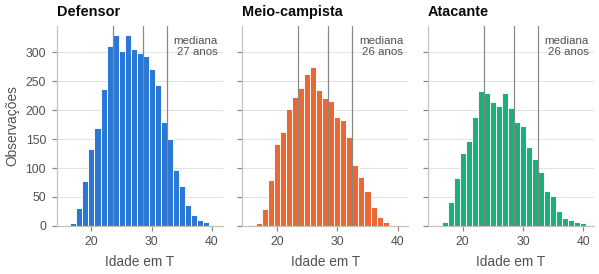

In [15]:
fig, axes = plt.subplots(1, 3, figsize=pl.figsize(6), sharey=True, gridspec_kw={"wspace": 0.12})
bins = np.arange(15.5, 41.5, 1)
for ax, pos in zip(axes, POS):
    ages = sample.loc[sample["position_group"] == pos, "age_T"].astype(float)
    ax.hist(ages, bins=bins, color=pl.POSITION_COLORS[pos], edgecolor=pl.SURFACE, linewidth=0.6)
    for edge in (23.5, 28.5, 32.5):
        ax.axvline(edge, color=pl.INK_MUTED, linewidth=0.8)
    ax.set_title(sp.POSITION_LABELS[pos])
    ax.text(0.97, 0.95, f"mediana\n{ages.median():.0f} anos", transform=ax.transAxes, ha="right", va="top",
            fontsize=7.5, color=pl.INK_SECONDARY)
    ax.set_xlabel("Idade em T")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Observações")
FIG.save(fig, "fig08_idade_por_posicao",
         "Distribuição da idade em T por posição, com os limites das faixas etárias",
         note="Linhas verticais separam as faixas 16–23, 24–28, 29–32 e 33+ anos.")
plt.show()

**Leitura.** Todas as 12 células têm tamanho suficiente para modelagem segmentada, mas há forte
desbalanceamento:

- **C4 (DEF 24–28)** concentra 16,0% da amostra (1.567 observações).
- As três categorias de veteranos (C10–C12) somam 9,8%, entre 268 e 389 observações.

Na janela expandida, a primeira dobra treina com uma única temporada. C12 (ATA 33+) teria apenas
40 observações de treino em 2019/20, e cerca de 210 com alvo $T+2$ no total. Isso sugere duas
coisas para o notebook 04:

1. Exigir um número mínimo de observações de treino por dobra (ou iniciar a janela em 2020/21 para
   as categorias de veteranos).
2. Comparar o modelo segmentado com um **modelo global que recebe faixa etária e posição como
   *features***, que serve de *baseline* de segmentação.

A Figura 8 mostra que as idades medianas são de 27 anos (defensores) e 26 anos (meio-campistas e
atacantes). Os limites das faixas cortam a distribuição em regiões densas, o que torna a
classificação sensível à data de referência da idade. A convenção adotada (anos completos em 30 de
junho de $T$, mesma âncora de $V_T$) deve constar no texto.

*Nota sobre a especificação:* a numeração C1–C12 segue a Tabela 5.2 (*Verificação dos Dados*) e a
Tabela 6.2 (*Design do Modelo*): faixa etária nas linhas e DEF/MEI/ATA nas colunas. A Tabela 3.1
da *Metodologia* numera os subgrupos por coluna (Subgrupo 2 = DEF 24–28). Convém uniformizar no
artigo. Os rótulos nominais "24–28" e "28–32" também se sobrepõem em 28 anos, e a leitura formal
adotada aqui é 24–28 e 29–32 anos completos.

## 7. Variáveis-alvo: $\Delta V$, $\Delta V\%$ e log-retorno

A literatura descreve as variações de valor como fortemente assimétricas à direita (Hill et al.,
2025; Müller et al., 2017). Verifica-se aqui a magnitude dessa assimetria e a massa de
**variações nulas**. Essa massa é característica do Transfermarkt, que só revisa valores
periodicamente e em degraus arredondados. Também se avalia se o log-retorno
$\ln(V_{T+k}/V_T)$, monotônico em $\Delta V\%$, produz uma distribuição mais adequada à perda
quadrática dos modelos.

In [16]:
target_cols = {
    "V_T (€ mi)": sample["tm_value_T"] / 1e6,
    "log10 V_T": np.log10(sample["tm_value_T"]),
    "ΔV T+1 (€ mi)": sample["delta_v_T1"] / 1e6, "ΔV T+2 (€ mi)": sample["delta_v_T2"] / 1e6,
    "ΔV% T+1": sample["delta_v_pct_T1"], "ΔV% T+2": sample["delta_v_pct_T2"],
    "log-retorno T+1": sample["log_return_T1"], "log-retorno T+2": sample["log_return_T2"],
}
rows = {}
for name, s in target_cols.items():
    s = s.dropna()
    rows[name] = {"n": len(s), "média": s.mean(), "mediana": s.median(), "desvio-padrão": s.std(),
                  "p1": s.quantile(0.01), "p99": s.quantile(0.99), "assimetria": stats.skew(s),
                  "curtose (excesso)": stats.kurtosis(s), "% = 0": (s == 0).mean() * 100}
target_stats = pd.DataFrame(rows).T
save_csv(target_stats, "tab11_estatisticas_alvos")
target_stats.round(2)

,n,média,mediana,desvio-padrão,p1,p99,assimetria,curtose (excesso),% = 0
V_T (€ mi),"9,810.00",7.37,4.50,7.26,0.30,30.00,1.33,0.94,0.00
log10 V_T,"9,810.00",6.64,6.65,0.49,5.48,7.48,-0.28,-0.54,0.00
ΔV T+1 (€ mi),"9,648.00",-0.12,-0.50,5.58,-12.00,21.00,2.95,21.60,10.56
ΔV T+2 (€ mi),"9,438.00",-0.48,-1.00,8.34,-18.00,32.00,2.93,18.83,4.70
ΔV% T+1,"9,648.00",8.92,-20.00,171.34,-77.14,455.56,19.52,634.07,10.56
ΔV% T+2,"9,438.00",17.11,-37.50,324.86,-93.75,900.00,21.18,635.78,4.70
log-retorno T+1,"9,617.00",-0.16,-0.22,0.60,-1.39,1.71,1.02,3.73,10.60
log-retorno T+2,"9,357.00",-0.38,-0.47,0.89,-2.30,2.30,0.70,1.67,4.75


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig09_distribuicao_alvos.png


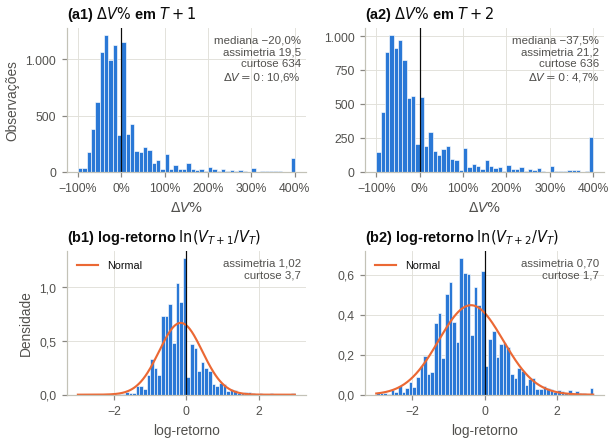

In [17]:
fig, axes = plt.subplots(2, 2, figsize=pl.figsize(11), gridspec_kw={"hspace": 0.55, "wspace": 0.25})
for col, k in enumerate((1, 2)):
    s = sample[f"delta_v_pct_T{k}"].dropna()
    ax = axes[0, col]
    ax.hist(s.clip(-100, 400), bins=np.arange(-100, 410, 10), color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.4)
    ax.axvline(0, color=pl.INK, linewidth=0.8)
    ax.set_title(f"(a{k}) $\\Delta V\\%$ em $T+{k}$")
    ax.set_xlabel("$\\Delta V\\%$")
    ax.xaxis.set_major_formatter(pl.pct_formatter(0))
    ax.yaxis.set_major_formatter(pl.br_formatter(0))
    ax.text(0.98, 0.95, f"mediana {pl.br_pct(s.median(), 1)}\nassimetria {pl.br(stats.skew(s), 1)}\n"
            f"curtose {pl.br(stats.kurtosis(s), 0)}\n$\\Delta V = 0$: {pl.br_pct((s == 0).mean() * 100, 1)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=pl.INK_SECONDARY)
    lr = sample[f"log_return_T{k}"].dropna()
    ax = axes[1, col]
    ax.hist(lr.clip(-3, 3), bins=np.arange(-3, 3.05, 0.1), color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.4,
            density=True)
    grid = np.linspace(-3, 3, 300)
    ax.plot(grid, stats.norm.pdf(grid, lr.mean(), lr.std()), color=pl.ORANGE, linewidth=1.4, label="Normal")
    ax.axvline(0, color=pl.INK, linewidth=0.8)
    ax.set_title(f"(b{k}) log-retorno $\\ln(V_{{T+{k}}}/V_T)$")
    ax.set_xlabel("log-retorno")
    ax.xaxis.set_major_formatter(pl.br_formatter(0))
    ax.yaxis.set_major_formatter(pl.br_formatter(1))
    ax.text(0.98, 0.95, f"assimetria {pl.br(stats.skew(lr), 2)}\ncurtose {pl.br(stats.kurtosis(lr), 1)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=pl.INK_SECONDARY)
    ax.legend(loc="upper left", fontsize=7)
axes[0, 0].set_ylabel("Observações")
axes[1, 0].set_ylabel("Densidade")
FIG.save(fig, "fig09_distribuicao_alvos",
         "Distribuição da variação percentual do valor de mercado e do log-retorno em T+1 e T+2",
         note="Amostra analítica (após o corte p90). Em (a), valores acima de 400% acumulados no último intervalo.")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig10_direcao_variacao.png


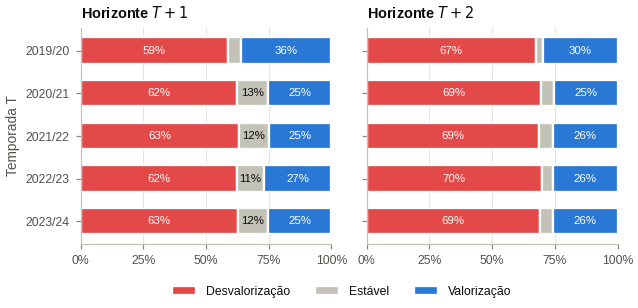

In [18]:
def direction_shares(k: int) -> pd.DataFrame:
    d = sample[["season", f"delta_v_T{k}"]].dropna()
    sign = np.sign(d[f"delta_v_T{k}"]).map({-1: "Desvalorização", 0: "Estável", 1: "Valorização"})
    out = pd.crosstab(d["season"], sign, normalize="index") * 100
    out.index = [sp.season_label(s) for s in out.index]
    return out.reindex(columns=["Desvalorização", "Estável", "Valorização"])


dir1, dir2 = direction_shares(1), direction_shares(2)
save_csv(pd.concat({"T+1": dir1, "T+2": dir2}), "tab12_direcao_variacao_temporada")
colors = {"Desvalorização": pl.RED, "Estável": pl.NEUTRAL, "Valorização": pl.BLUE}
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=True, gridspec_kw={"wspace": 0.14})
for ax, (k, d) in zip(axes, ((1, dir1), (2, dir2))):
    d = d.iloc[::-1]
    left = np.zeros(len(d))
    for cat in d.columns:
        ax.barh(range(len(d)), d[cat], left=left, color=colors[cat], height=0.62, label=cat,
                edgecolor=pl.SURFACE, linewidth=1.5)
        for i, (l, v) in enumerate(zip(left, d[cat])):
            if v >= 8:
                ax.text(l + v / 2, i, pl.br_pct(v, 0), ha="center", va="center", fontsize=7.5,
                        color=pl.INK if cat == "Estável" else pl.SURFACE)
        left += d[cat].to_numpy()
    ax.set_yticks(range(len(d)), d.index)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"Horizonte $T+{k}$")
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Temporada T")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.04, -0.14), ncol=3, frameon=False)
FIG.save(fig, "fig10_direcao_variacao",
         "Proporção de atletas com valorização, estabilidade e desvalorização de mercado por temporada de referência",
         note="Temporada T de 2023/24 em T+2 corresponde a V observado em 30/06/2026.")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig11_alvos_por_categoria.png


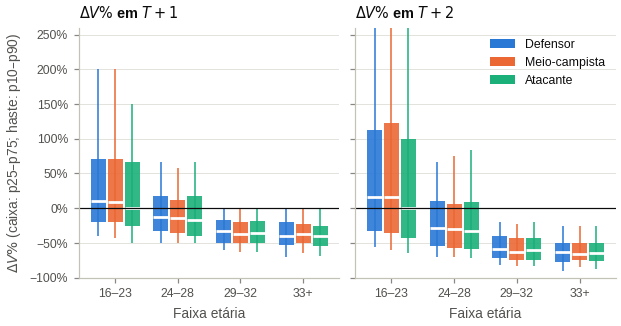

mediana        %_valorizou      
horizonte          T+1    T+2         T+1   T+2
categoria                                      
C1 · DEF 16–23   10.30  16.70       52.20 53.80
C10 · DEF 33+   -40.00 -62.50        4.20  2.40
C11 · MEI 33+   -37.50 -65.70        1.90  0.40
C12 · ATA 33+   -40.00 -64.30        5.30  1.90
C2 · MEI 16–23    9.40  16.70       51.00 54.20
C3 · ATA 16–23    0.00   0.00       44.60 49.10
C4 · DEF 24–28  -12.00 -28.00       31.50 26.90
C5 · MEI 24–28  -14.30 -30.00       29.60 25.70
C6 · ATA 24–28  -16.70 -33.30       30.60 27.10
C7 · DEF 29–32  -33.30 -59.10        7.50  3.00
C8 · MEI 29–32  -37.50 -62.50        5.70  3.80
C9 · ATA 29–32  -35.70 -60.80        6.20  4.60

In [19]:
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7.5), sharey=True, gridspec_kw={"wspace": 0.06})
width = 0.24
summary_rows = []
for ax, k in zip(axes, (1, 2)):
    col = f"delta_v_pct_T{k}"
    for b, band in enumerate(BANDS):
        for p, pos in enumerate(POS):
            s = sample.loc[(sample["age_band"] == band) & (sample["position_group"] == pos), col].dropna()
            if s.empty:
                continue
            x = b + (p - 1) * (width + 0.03)
            q10, q25, q50, q75, q90 = s.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
            ax.vlines(x, q10, q90, color=pl.POSITION_COLORS[pos], linewidth=1)
            ax.add_patch(plt.Rectangle((x - width / 2, q25), width, q75 - q25, color=pl.POSITION_COLORS[pos],
                                       alpha=0.9, linewidth=0))
            ax.hlines(q50, x - width / 2, x + width / 2, color=pl.SURFACE, linewidth=1.8)
            summary_rows.append({"horizonte": f"T+{k}", "categoria": CAT_LABELS[f"C{b * 3 + p + 1}"], "n": len(s),
                                 "p10": q10, "p25": q25, "mediana": q50, "p75": q75, "p90": q90,
                                 "media": s.mean(), "%_valorizou": (s > 0).mean() * 100})
    ax.axhline(0, color=pl.INK, linewidth=0.8)
    ax.set_xticks(range(len(BANDS)), BANDS)
    ax.set_xlabel("Faixa etária")
    ax.set_title(f"$\\Delta V\\%$ em $T+{k}$")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$\\Delta V\\%$ (caixa: p25–p75; haste: p10–p90)")
axes[0].yaxis.set_major_formatter(pl.pct_formatter(0))
axes[0].set_ylim(-100, 260)
handles = [plt.Rectangle((0, 0), 1, 1, color=pl.POSITION_COLORS[p]) for p in POS]
axes[1].legend(handles, [sp.POSITION_LABELS[p] for p in POS], loc="upper right")
cat_targets = pd.DataFrame(summary_rows)
save_csv(cat_targets, "tab13_alvos_por_categoria", index=False)
FIG.save(fig, "fig11_alvos_por_categoria",
         "Distribuição da variação percentual do valor de mercado por categoria (faixa etária × posição)",
         note="Linha branca: mediana. Eixo vertical truncado em [−100%, 260%].")
plt.show()
cat_targets.pivot(index="categoria", columns="horizonte", values=["mediana", "%_valorizou"]).round(1)

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig12_curva_idade.png


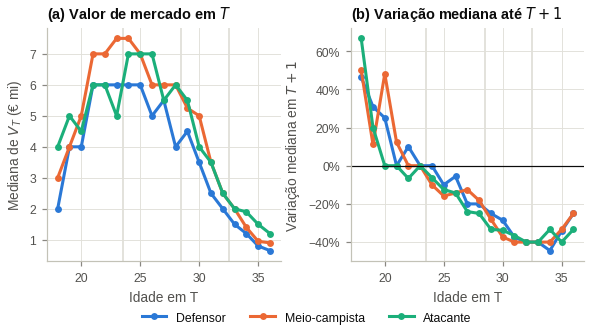

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(7), gridspec_kw={"wspace": 0.3})
age_curve = []
for pos in POS:
    d = sample[sample["position_group"] == pos].assign(age=lambda x: x["age_T"].astype(float).clip(17, 36))
    g = d.groupby("age").agg(n=("log_return_T1", "count"), mediana_lr_T1=("log_return_T1", "median"),
                             media_dvpct_T1=("delta_v_pct_T1", "mean"), mediana_vt=("tm_value_T", "median"))
    g = g[g["n"] >= 25]
    age_curve.append(g.assign(posicao=pos))
    ax1.plot(g.index, g["mediana_vt"] / 1e6, color=pl.POSITION_COLORS[pos], marker="o", markersize=3.5,
             label=sp.POSITION_LABELS[pos])
    ax2.plot(g.index, np.expm1(g["mediana_lr_T1"]) * 100, color=pl.POSITION_COLORS[pos], marker="o",
             markersize=3.5, label=sp.POSITION_LABELS[pos])
for ax in (ax1, ax2):
    for edge in (23.5, 28.5, 32.5):
        ax.axvline(edge, color=pl.GRID, linewidth=1.2, zorder=0)
    ax.set_xlabel("Idade em T")
ax1.set_ylabel("Mediana de $V_T$ (€ mi)")
ax1.yaxis.set_major_formatter(pl.br_formatter(0))
ax1.set_title("(a) Valor de mercado em $T$")
ax2.axhline(0, color=pl.INK, linewidth=0.8)
ax2.yaxis.set_major_formatter(pl.pct_formatter(0))
ax2.set_ylabel("Variação mediana em $T+1$")
ax2.set_title("(b) Variação mediana até $T+1$")
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3)
save_csv(pd.concat(age_curve), "tab14_curva_idade")
FIG.save(fig, "fig12_curva_idade",
         "Valor de mercado mediano em T e variação mediana em T+1 por idade e posição",
         note="Idades com ao menos 25 observações; extremos agregados em 17 e 36 anos. Variação mediana = exp(mediana do log-retorno) − 1.")
plt.show()

**Leitura.** Três resultados centrais para a seção de Verificação dos Dados e para o desenho dos
modelos:

1. **$\Delta V\%$ é extremamente assimétrico e leptocúrtico.** Em $T+1$ a assimetria é 19,5 e a
   curtose em excesso é 634. A média (+8,9%) e a mediana (−20,0%) têm sinais opostos: a cauda
   direita de 6,7% de atletas que mais que dobram de valor domina a média. Com perda quadrática,
   RMSE e $R^2$ calculados sobre $\Delta V\%$ bruto seriam governados por poucas observações
   extremas. **Recomenda-se modelar o log-retorno** $\ln(V_{T+k}/V_T)$, cuja assimetria é 1,02
   ($T+1$) e 0,70 ($T+2$), e reconverter as previsões para $\Delta V\% = e^{\hat{y}} - 1$ na
   interpretação. Alternativamente, pode-se manter $\Delta V\%$ com perda robusta (Huber) e
   reportar o MAE como métrica principal.
2. **A variação típica é de desvalorização.** De 2020/21 em diante, 62–63% dos atletas perdem
   valor até $T+1$ (59% em 2019/20), e 67–70% até $T+2$. Cerca de 11% ficam estáveis, porque o Transfermarkt
   revisa valores em degraus e com baixa frequência. A exceção é 2019/20 (36% de valorização), cujo
   $V_T$ foi medido logo após a revisão geral para baixo de abril de 2020 (pandemia) e cuja
   variação seguinte inclui a recuperação. Isso recomenda **efeitos de temporada** (ou um alvo
   relativo à mediana da temporada) nos modelos.
3. **A idade é o determinante dominante da direção da variação** (Figuras 11 e 12).
   - **16–23 anos (C1–C3):** as únicas categorias com mediana positiva (+9% a +10% em $T+1$ para
     DEF e MEI, 0% para ATA), com a maior dispersão.
   - **24–28 anos:** valorização em cerca de 30% dos casos e mediana entre −12% e −17%.
   - **29 anos ou mais:** valorização em menos de 8% dos casos e mediana entre −33% e −40% ao ano.
   A curva de valor mediano em $T$ é côncava, com pico entre 23 e 26 anos, e a variação até $T+1$
   cruza zero por volta dos 22–24 anos. Ambas sustentam empiricamente a inclusão de idade e
   $\text{idade}^2$ e a separação das faixas 29–32 e 33+ proposta na especificação. A
   heterogeneidade entre posições dentro de uma mesma faixa é pequena frente à heterogeneidade
   entre faixas, o que sugere que a idade é o eixo principal da segmentação.

## 8. Associação bivariada entre desempenho em $T$ e valorização

Prévia exploratória da relevância das métricas tático-técnicas, antes da engenharia de *features*
do notebook 03. Para cada métrica por 90 minutos (com os minutos da própria fonte no denominador),
calcula-se a correlação de postos de Spearman com $\Delta V\%_{T+1}$ dentro de cada posição. Como
$\Delta V\%$ e o log-retorno são transformações monotônicas uma da outra, o $\rho$ de Spearman é
idêntico para ambos.

A correlação bruta (a) não controla idade nem $V_T$, que são confundidores fortes: um atleta jovem
tende a ter, ao mesmo tempo, menos minutos e maior valorização. Por isso também se reporta a
correlação **parcial** (b). Os postos da métrica e do alvo são residualizados por mínimos quadrados
sobre idade, idade², $\log V_T$ e efeitos fixos de temporada, e então correlacionados. Os dois
painéis servem para orientar a engenharia de *features*, e não para inferência causal.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig13_correlacao_desempenho_valorizacao.png


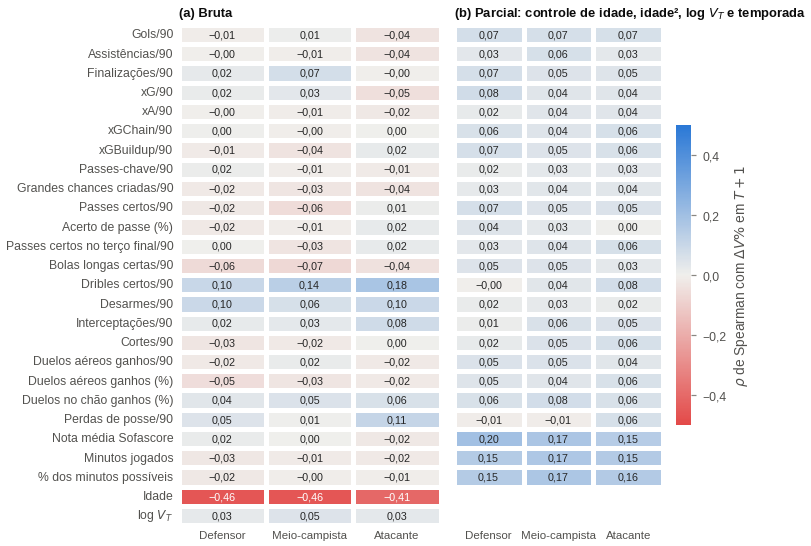

,Defensor,Meio-campista,Atacante
Acerto de passe (%),0.04,0.03,0.00
Desarmes/90,0.02,0.03,0.02
Assistências/90,0.03,0.06,0.03
Passes-chave/90,0.02,0.03,0.03
Bolas longas certas/90,0.05,0.05,0.03
Grandes chances criadas/90,0.03,0.04,0.04
xA/90,0.02,0.04,0.04
xG/90,0.08,0.04,0.04
Duelos aéreos ganhos/90,0.05,0.05,0.04
Interceptações/90,0.01,0.06,0.05


In [21]:
def per90(num: str, minutes: str) -> pd.Series:
    m = sample[minutes].where(sample[minutes] > 0)
    return sample[num] / m * 90


metric_defs = {
    "Gols/90": per90("fb_goals", "fb_minutes"), "Assistências/90": per90("fb_assists", "fb_minutes"),
    "Finalizações/90": per90("fb_shots", "fb_minutes"),
    "xG/90": per90("us_xg", "us_minutes"), "xA/90": per90("us_xa", "us_minutes"),
    "xGChain/90": per90("us_xg_chain", "us_minutes"), "xGBuildup/90": per90("us_xg_buildup", "us_minutes"),
    "Passes-chave/90": per90("ss_key_passes", "ss_minutes_played"),
    "Grandes chances criadas/90": per90("ss_big_chances_created", "ss_minutes_played"),
    "Passes certos/90": per90("ss_accurate_passes", "ss_minutes_played"),
    "Acerto de passe (%)": sample["ss_accurate_passes_percentage"],
    "Passes certos no terço final/90": per90("ss_accurate_final_third_passes", "ss_minutes_played"),
    "Bolas longas certas/90": per90("ss_accurate_long_balls", "ss_minutes_played"),
    "Dribles certos/90": per90("ss_successful_dribbles", "ss_minutes_played"),
    "Desarmes/90": per90("ss_tackles", "ss_minutes_played"),
    "Interceptações/90": per90("ss_interceptions", "ss_minutes_played"),
    "Cortes/90": per90("ss_clearances", "ss_minutes_played"),
    "Duelos aéreos ganhos/90": per90("ss_aerial_duels_won", "ss_minutes_played"),
    "Duelos aéreos ganhos (%)": sample["ss_aerial_duels_won_percentage"],
    "Duelos no chão ganhos (%)": sample["ss_ground_duels_won_percentage"],
    "Perdas de posse/90": per90("ss_possession_lost", "ss_minutes_played"),
    "Nota média Sofascore": sample["ss_rating"],
    "Minutos jogados": sample["fb_minutes"], "% dos minutos possíveis": sample["fb_minutes_pct"],
    "Idade": sample["age_T"].astype(float), "log $V_T$": np.log(sample["tm_value_T"]),
}
metrics = pd.DataFrame(metric_defs)
perf_cols = [c for c in metrics.columns if c not in ("Idade", "log $V_T$")]


def residualize(values: np.ndarray, design: np.ndarray) -> np.ndarray:
    beta, *_ = np.linalg.lstsq(design, values, rcond=None)
    return values - design @ beta


def partial_spearman(x: pd.Series, y: pd.Series, controls: pd.DataFrame) -> float:
    # Spearman parcial: correlação de Pearson entre os postos de x e y após remover dos dois a
    # parte linear explicada pelos controles.
    ok = x.notna() & y.notna() & controls.notna().all(axis=1)
    if ok.sum() < 30:
        return np.nan
    design = np.column_stack([np.ones(ok.sum()), controls[ok].to_numpy(float)])
    rx = residualize(x[ok].rank().to_numpy(float), design)
    ry = residualize(y[ok].rank().to_numpy(float), design)
    return float(np.corrcoef(rx, ry)[0, 1])


age = sample["age_T"].astype(float)
controls = pd.concat([age.rename("idade"), (age ** 2).rename("idade2"),
                      np.log(sample["tm_value_T"]).rename("log_vt"),
                      pd.get_dummies(sample["season"], prefix="s", drop_first=True, dtype=float)], axis=1)
corr_raw, corr_partial = {}, {}
for pos in POS:
    mask = sample["position_group"] == pos
    y = sample.loc[mask, "delta_v_pct_T1"]
    corr_raw[sp.POSITION_LABELS[pos]] = metrics[mask].apply(lambda x: x.corr(y, method="spearman"))
    corr_partial[sp.POSITION_LABELS[pos]] = pd.Series(
        {c: partial_spearman(metrics.loc[mask, c], y, controls[mask]) for c in perf_cols})
corr_raw, corr_partial = pd.DataFrame(corr_raw), pd.DataFrame(corr_partial)
save_csv(pd.concat({"bruta": corr_raw, "parcial": corr_partial}, axis=1), "tab15_spearman_metricas_dvpct_t1")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(15), sharey=True, gridspec_kw={"wspace": 0.05})
lim = 0.5
for ax, data, title in ((ax1, corr_raw, "(a) Bruta"), (ax2, corr_partial.reindex(corr_raw.index),
                                                         "(b) Parcial: controle de idade, idade², log $V_T$ e temporada")):
    sns.heatmap(data, annot=pl.annotations(data, 2), fmt="", cmap=pl.DIVERGING, vmin=-lim, vmax=lim, center=0,
                linewidths=2, linecolor=pl.SURFACE, cbar=ax is ax2, ax=ax, annot_kws={"fontsize": 7},
                cbar_kws={"label": "$\\rho$ de Spearman com $\\Delta V\\%$ em $T+1$", "shrink": 0.6})
    ax.set_title(title, fontsize=8.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(length=0)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(False)
ax2.collections[0].colorbar.ax.yaxis.set_major_formatter(pl.br_formatter(1))
FIG.save(fig, "fig13_correlacao_desempenho_valorizacao",
         "Correlação de Spearman entre métricas de desempenho em T e a variação percentual do valor em T+1, por posição",
         note="Métricas por 90 minutos usam os minutos da própria fonte. Em (b), postos residualizados por OLS "
              "sobre idade, idade², log V_T e efeitos de temporada.")
plt.show()
corr_partial.round(2).sort_values("Atacante")

**Leitura.** Sem controles (painel a), as métricas de desempenho praticamente não se associam a
$\Delta V\%_{T+1}$ ($|\rho| \le 0{,}10$ na maioria), enquanto a idade domina ($\rho \approx -0{,}45$
nas três posições). As exceções aparentes (dribles certos/90, desarmes/90) são, em boa parte,
reflexo da idade, porque atletas jovens driblam e desarmam mais.

**Após controlar idade, idade², $\log V_T$ e temporada (painel b), o sinal de desempenho emerge de
forma consistente e positiva nas três posições:**

- **Nota média do Sofascore:** $\rho$ parcial de 0,15–0,20.
- **Minutagem:** minutos jogados e percentual de minutos possíveis, ambos com 0,15–0,17.
- **Métricas ofensivas e de construção:** gols/90, xG/90, xGBuildup/90 e passes certos/90, entre
  0,04 e 0,08.

Interpretação: condicionado à idade e ao nível de preço, o mercado premia sobretudo **regularidade
e titularidade** (minutos) e **avaliação agregada de desempenho**, mais do que qualquer métrica
tática isolada. Com magnitudes bivariadas modestas, espera-se que o ganho preditivo venha de
**interações** (desempenho × idade × posição), que os modelos de árvores capturam e o SHAP poderá
decompor no notebook 05. A minutagem, que a especificação trata como filtro, aparece aqui como
*feature* informativa e deve ser mantida no vetor explicativo.

## 9. Defasagem das avaliações em relação à data-âncora

$V_{T+k}$ é o último valor publicado até 30/jun do ano de término da temporada, aceito se tiver no
máximo 183 dias. A defasagem mede quanto o valor usado pode estar desatualizado frente à
data-âncora. O Transfermarkt concentra as revisões em janelas (fim e meio de temporada), o que
aparece como picos na distribuição.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda/fig14_defasagem_avaliacoes.png


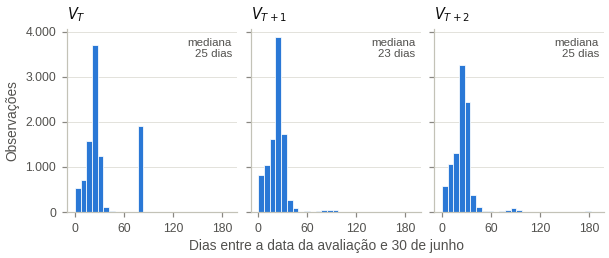

,V_T,V_{T+1},V_{T+2}
count,"9,810.00","9,648.00","9,438.00"
mean,33.60,23.10,25.40
std,25.80,14.80,17.00
min,0.00,0.00,0.00
25%,20.00,15.00,16.00
50%,25.00,23.00,25.00
75%,32.00,27.00,31.00
90%,83.00,33.00,34.00
max,176.00,183.00,183.00


In [22]:
fig, axes = plt.subplots(1, 3, figsize=pl.figsize(5.5), sharey=True, gridspec_kw={"wspace": 0.08})
stale_summary = {}
for ax, (label, col) in zip(axes, (("V_T", "tm_value_days_stale_T"), ("V_{T+1}", "tm_value_days_stale_T1"),
                                   ("V_{T+2}", "tm_value_days_stale_T2"))):
    s = sample[col].dropna()
    stale_summary[label] = s.describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    ax.hist(s, bins=np.arange(0, 190, 7), color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.5)
    ax.set_title(f"${label}$")
    ax.text(0.97, 0.95, f"mediana\n{s.median():.0f} dias", transform=ax.transAxes, ha="right", va="top",
            fontsize=7.5, color=pl.INK_SECONDARY)
    ax.set_xticks([0, 60, 120, 180])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Observações")
axes[0].yaxis.set_major_formatter(pl.br_formatter(0))
fig.supxlabel("Dias entre a data da avaliação e 30 de junho", fontsize=9, color=pl.INK_SECONDARY, y=-0.06)
save_csv(pd.DataFrame(stale_summary), "tab16_defasagem_avaliacoes")
FIG.save(fig, "fig14_defasagem_avaliacoes",
         "Defasagem entre a data da última avaliação do Transfermarkt e a data-âncora (30 de junho)")
plt.show()
pd.DataFrame(stale_summary).round(1)

**Leitura.** A mediana da defasagem é de 23–25 dias nos três horizontes, e ao menos 75% das
avaliações têm no máximo 32 dias. As datas-âncora (30 de junho) ficam próximas da janela de revisão
de fim de temporada do Transfermarkt, o que confirma a escolha. A exceção estrutural é 2019/20:
99% dos $V_T$ dessa temporada datam de **8 de abril de 2020**, a revisão geral extraordinária feita
pelo Transfermarkt no início da pandemia, sem atualização posterior até a âncora. O pico em torno
de 80 dias no primeiro painel corresponde a essas observações. Esse ponto deve constar nas
limitações. Ele também explica o comportamento atípico de 2019/20 na Figura 10.

## 10. Índice de figuras e tabelas exportadas

In [23]:
index = FIG.write_index()
print(f"{len(index)} figuras em {FIG.directory}")
print(f"{len(list(TABLES.glob('*.csv')))} tabelas em {TABLES}")
display(index[["figura", "arquivo", "legenda"]])

14 figuras em /home/alvaro/Documents/TCC/football-analytics/reports/figures/02_eda
18 tabelas em /home/alvaro/Documents/TCC/football-analytics/reports/tables/02_eda


,figura,arquivo,legenda
0,1,fig01_funil_amostral.png,Funil de seleção da amostra analítica (Big Fiv...
1,2,fig02_distribuicao_vt.png,Distribuição do valor de mercado em T e limiar...
2,3,fig03_p90_liga_temporada.png,Percentil 90 do valor de mercado em T por liga...
3,4,fig04_perfil_excluidos_p90.png,Proporção de observações acima do percentil 90...
4,5,fig05_minutagem.png,Distribuição dos minutos jogados em T e propor...
5,6,fig06_ausentes.png,Proporção de valores ausentes por variável e t...
6,7,fig07_matriz_12_categorias.png,Distribuição da amostra analítica na matriz de...
7,8,fig08_idade_por_posicao.png,"Distribuição da idade em T por posição, com os..."
8,9,fig09_distribuicao_alvos.png,Distribuição da variação percentual do valor d...
9,10,fig10_direcao_variacao.png,"Proporção de atletas com valorização, estabili..."


## 11. Síntese para o artigo

**Decisões validadas**
1. **Filtros.** O funil de seleção reproduz as ordens de grandeza da especificação: amostra final
   de 9.810 observações e 4.084 atletas (especificação: 10.350 e 4.217).
2. **Minutagem.** O filtro de 90 minutos afeta sobretudo jovens de 16–23 anos (23% da faixa) e não
   corta nenhuma concentração natural da distribuição.
3. **Matriz 4 × 3.** As 12 categorias têm entre 268 (C12) e 1.567 (C4) observações, e as variações
   de valor diferem fortemente entre faixas etárias, o que justifica a segmentação.

**Ajustes recomendados para o texto e para os notebooks seguintes**
1. **Limiar do corte.** O $p_{90}$ efetivo é de € 27–32 mi, não € 18 mi. Apresentar € 18 mi como
   referência histórica (Müller et al., 2017) e adotar o $p_{90}$ por temporada. O corte por liga
   e temporada fica como teste de robustez.
2. **Alvo principal.** Modelar o **log-retorno**, porque $\Delta V\%$ tem assimetria de 19,5 e
   curtose de 634. Reportar também MAE e métricas por categoria em $\Delta V\%$ reconvertido.
3. **Variáveis a manter e a descartar.** Incluir efeitos de temporada e manter a minutagem como
   *feature*. Descartar as métricas do Sofascore sem cobertura histórica (recuperações, bloqueios,
   xG/xA do Sofascore).
4. **Viés de sobrevivência.** Tratar a ausência de $V_{T+k}$ como exclusão e documentar o viés nas
   categorias C10–C12.
5. **Numeração das categorias.** Uniformizar C1–C12 entre a Metodologia (Tabela 3.1) e a
   Verificação dos Dados (Tabela 5.2).

**Limitações a registrar**
- Corte assimétrico entre ligas (21% da Premier League excluída).
- Revisão de abril de 2020 no $V_T$ de 2019/20.
- Contrato em $T$ estimado, não observado.
- Seleção de jovens com minutagem na elite.

**Arquivos**
- Figuras: `reports/figures/02_eda/` (índice de legendas em `figures_index.md`).
- Tabelas: `reports/tables/02_eda/`.